In [ ]:
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from pathlib import Path

from multiprocessing import Pool
import sys
from astropy.io import fits

In [ ]:
name_fields = ['XMM', 'VVDS', 'GAMA09H', 'GAMA15H', 'WIDE12H', 'HECTOMAP']
number_patches = [8, 25, 23, 7, 26, 13]
_GALAXY_COUNTS_TOMOBIN_ = {}

for field, Npatch in zip(name_fields, number_patches):
    dats = [
        fits.getdata(f'~/HSCNG/data/real/hscy3_shape_chopped_{field}_{i}.fits')
        for i in range(Npatch)
    ]
    dat = np.concatenate(dats)
    _numbers = []
    for tomo_bin in [1, 2, 3, 4]:
        _numbers.append((dat['hsc_y3_zbin'] == tomo_bin).sum())
    _GALAXY_COUNTS_TOMOBIN_[field] = _numbers

In [ ]:
stats = 'Gabriela'
Cl_tomo = []
for tomo in [1, 2, 3, 4]:
    Cl_cosmo_varied = []
    for cosmology_id in range(50):
        Cls = []
        for field in name_fields:
            if stats == 'Gabriela':
                dat = np.load(f'/lustre/work/gmarques/HSC_Y3_analysis_Gabriela/stats_cosmo_varied/power_spectrum/model{cosmology_id}_Clee_z{tomo}_{field}.npy')     # 50 realizations here
            elif stats == 'DI':
                dat = np.load(f'/home/hedi/HSCNG/power/mock_results/model{cosmology_id}_power_z{tomo}_{field}.npy')     # 50 realizations here
            Cls.append(dat)
        Cls = np.array(Cls)
        weights = [
            _GALAXY_COUNTS_TOMOBIN_[field][tomo - 1] for field in name_fields
        ]
        Cl_cosmo_varied.append(np.average(Cls, axis=0, weights=weights))

    Cl_tomo.append(np.array(Cl_cosmo_varied))
Cl_G = np.array(Cl_tomo)

stats = 'DI'
Cl_tomo = []
for tomo in [1, 2, 3, 4]:
    Cl_cosmo_varied = []
    for cosmology_id in range(50):
        Cls = []
        for field in name_fields:
            if stats == 'Gabriela':
                dat = np.load(f'/lustre/work/gmarques/HSC_Y3_analysis_Gabriela/stats_cosmo_varied/power_spectrum/model{cosmology_id}_Clee_z{tomo}_{field}.npy')     # 50 realizations here
            elif stats == 'DI':
                dat = np.load(f'/home/hedi/HSCNG/power/mock_results/model{cosmology_id}_power_z{tomo}_{field}.npy')     # 50 realizations here
            Cls.append(dat)
        Cls = np.array(Cls)
        weights = [
            _GALAXY_COUNTS_TOMOBIN_[field][tomo - 1] for field in name_fields
        ]
        Cl_cosmo_varied.append(np.average(Cls, axis=0, weights=weights))

    Cl_tomo.append(np.array(Cl_cosmo_varied))
Cl_DI = np.array(Cl_tomo)

import pymaster as nmt
l_edges_log = np.unique(np.logspace(np.log10(80), np.log10(6500),15))
binner = nmt.NmtBinFlat(l_edges_log[:-1], l_edges_log[1:]) #Namaster power spectrum binner 
xx_G = binner.get_effective_ells()

l_edges_log = np.unique(np.logspace(np.log10(80), np.log10(6500), 20))
binner = nmt.NmtBinFlat(l_edges_log[:-1], l_edges_log[1:]) #Namaster power spectrum binner 
xx_DI = binner.get_effective_ells()

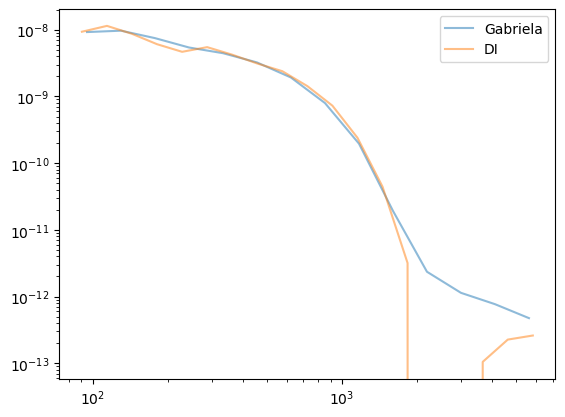

In [ ]:
tomo = 3
cosmo_id = 3
realization = 0
plt.plot(
    xx_G, Cl_G[tomo,cosmo_id,realization,:], label='Gabriela', alpha=0.5
)
plt.plot(
    xx_DI, Cl_DI[tomo,cosmo_id,realization,:], label='DI', alpha=0.5
)
plt.loglog()
plt.legend()
plt.show()